# ERA5-Driven Transport — Growing-Corridor Timelapse

Animated companion to panel **(a)** of `fig_transport_spatial.png`
(`notebooks/co_transport_temporal_coherence.ipynb`, Part D).

Panel (a) is a *still*: a fixed observed-CO background (the +1..+4 d composite,
cell-wise max enhancement) with the **full** ERA5 96-h corridor drawn as one
`p > 1%` contour. Here we keep that **CO background fixed** in every frame and
instead **grow the corridor over time**: frame +N d shows the ERA5 trajectory
corridor swept out by all 500 members up to age `N x 24 h`. The corridor
therefore *extends across days* (the plume front advances northward), while the
observed CO context underneath stays constant.

**ERA5-driven transport only** — no HYSPLIT. The trajectory ensemble is re-run
from the same priors/seed/config as `05_plume_pathway_ensemble.ipynb` using the
**current** data and code, so it is fully reproducible from this notebook alone.
The `+4 d` frame is the full 96-h corridor by construction; the saved
`outputs/pathway/corridor_prob.npy` (a cache that may predate the current
inputs) is compared as a diagnostic only, not required to match.

Outputs (under `outputs/transport_temporal/`):
- `fig_transport_corridor_timelapse.gif` — the growing-corridor timelapse
- `frame_corridor_+1d.png` .. `frame_corridor_+4d.png` — individual frames
- `fig_transport_corridor_filmstrip.png` — static 1x4 strip


In [1]:
from __future__ import annotations
import io, os, warnings
from collections import defaultdict
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shapely

warnings.filterwarnings('ignore')

_here = Path('.').resolve()
ROOT = next((p for p in [_here] + list(_here.parents)
             if (p / 'data').exists() and (p / 'src').exists()), None)
if ROOT is None:
    raise RuntimeError(f'Cannot locate project root from {_here}.')
os.chdir(ROOT)
print(f'Project root: {ROOT}')

from src.data_helpers import load_co_l2, load_aer_ai, load_aer_lh
from src.fire_clustering import load_modis_csv
from src import trajectory as T
from src import plume_helpers as ph

DATA_DIR = ROOT / 'data'
OUT_DIR  = ROOT / 'outputs' / 'transport_temporal'
OUT_DIR.mkdir(parents=True, exist_ok=True)

FIRE_LAT, FIRE_LON = -37.5484, -72.5545
FIRE_DATE = '2026-01-18'

plt.rcParams.update({
    'font.size': 10, 'axes.labelsize': 11, 'axes.titlesize': 11,
    'legend.fontsize': 9, 'xtick.labelsize': 9, 'ytick.labelsize': 9,
    'figure.dpi': 120, 'savefig.dpi': 150, 'axes.grid': True,
    'grid.alpha': 0.35, 'grid.linewidth': 0.4,
})


Project root: /Users/maperezc/Downloads/wildfires


## Config (explicit — no silent defaults)

Two parameter groups, both copied verbatim from their source notebooks so the
timelapse is numerically consistent with the pipeline:

- **Ensemble** — from `05_plume_pathway_ensemble.ipynb` (500 members, seed 42,
  RK4 30-min step, 96 h, injection-pressure + FRP-weighted spatial priors).
- **Map / observed CO** — from `co_transport_temporal_coherence.ipynb` Part D
  (0.25° grid, `QA >= 0.5`, p10 off-plume background, four downwind overpasses).


In [2]:
# ── Map / corridor grid (shared) : identical to nb05 corridor + Part D map ────
LAT_MIN, LAT_MAX = -45.0, -17.0
LON_MIN, LON_MAX = -90.0, -65.0
GRID_RES = 0.25

lat_edges = np.arange(LAT_MIN, LAT_MAX + GRID_RES, GRID_RES)
lon_edges = np.arange(LON_MIN, LON_MAX + GRID_RES, GRID_RES)
lat_ctrs  = 0.5 * (lat_edges[:-1] + lat_edges[1:])
lon_ctrs  = 0.5 * (lon_edges[:-1] + lon_edges[1:])
CORR_LON2D, CORR_LAT2D = np.meshgrid(lon_ctrs, lat_ctrs)

# ── Ensemble Monte-Carlo parameters (nb05) ───────────────────────────────────
N_SAMPLES       = 500
SEED            = 42
LAUNCH_HOUR_MIN = 10.0
LAUNCH_HOUR_MAX = 22.0
RUN_HOURS       = 96
DT_S            = 1800
AI_THRESHOLD          = 2.0
PRESSURE_MATCH_R_KM   = 450.0
LOCAL_FIRE_RADIUS_KM  = 200.0
ERA5_LAT = (-66.75, -7.0)
ERA5_LON = (-103.0, -43.25)

# ── Observed-CO parameters (Part D) ──────────────────────────────────────────
QA_MIN       = 0.5
BG_PCT       = 10.0
MC_THRESHOLD = 0.01     # corridor contour level (p > 1%), matches panel (a)

# ── Four downwind overpasses (folder, offset day, overpass datetime) — nb06 ──
OVERPASSES = [
    {'folder': '0119', 'offset': 1, 'dt': datetime(2026, 1, 19, 18, 57)},
    {'folder': '0120', 'offset': 2, 'dt': datetime(2026, 1, 20, 18, 39)},
    {'folder': '0121', 'offset': 3, 'dt': datetime(2026, 1, 21, 18, 20)},
    {'folder': '0122', 'offset': 4, 'dt': datetime(2026, 1, 22, 18,  1)},
]
for ov in OVERPASSES:
    ov['files'] = sorted((DATA_DIR / ov['folder']).glob('S5P_OFFL_L2__CO_____*.nc'))
    assert ov['files'], f"No CO L2 files in data/{ov['folder']}"
    ov['age_h'] = ov['offset'] * 24.0

print(f'Grid  : lat [{LAT_MIN}, {LAT_MAX}], lon [{LON_MIN}, {LON_MAX}] @ {GRID_RES} deg')
print(f'Ens.  : {N_SAMPLES} members, seed {SEED}, {RUN_HOURS} h, dt {DT_S}s')
print(f'CO    : QA >= {QA_MIN}, bg p{BG_PCT:.0f}, corridor contour p > {MC_THRESHOLD:.0%}')


Grid  : lat [-45.0, -17.0], lon [-90.0, -65.0] @ 0.25 deg
Ens.  : 500 members, seed 42, 96 h, dt 1800s
CO    : QA >= 0.5, bg p10, corridor contour p > 1%


## Fixed observed-CO background (+1..+4 d composite)

Identical to panel (a): per-day CO enhancement (overpass field minus its p10
off-plume background), then the cell-wise max over the four downwind days. This
single field is the constant backdrop for every animation frame.

In [3]:
# ── Bin observed CO per overpass, then composite (fixed background) ───────────
def bin_co_map(files) -> np.ndarray:
    la, lo, co = [], [], []
    for f in files:
        c = load_co_l2(f, lat_min=LAT_MIN, lat_max=LAT_MAX,
                        lon_min=LON_MIN, lon_max=LON_MAX, qa_threshold=QA_MIN * 100)
        la.append(c['lat']); lo.append(c['lon']); co.append(c['co'])
    la = np.concatenate(la); lo = np.concatenate(lo); co = np.concatenate(co)
    g = np.full((len(lat_ctrs), len(lon_ctrs)), np.nan)
    il = np.searchsorted(lat_edges[1:-1], la)
    jl = np.searchsorted(lon_edges[1:-1], lo)
    ok = np.isfinite(co)
    df = pd.DataFrame({'v': co[ok], 'i': il[ok], 'j': jl[ok]})
    for (i, j), v in df.groupby(['i', 'j'])['v'].mean().items():
        g[i, j] = v
    return g

obs_enh = {}
for ov in OVERPASSES:
    g = bin_co_map(ov['files'])
    bg = np.nanpercentile(g, BG_PCT)
    obs_enh[ov['offset']] = g - bg
    print(f"+{ov['offset']}d: bg(p{BG_PCT:.0f})={bg*1e3:.1f} mmol/m2, "
          f"peak enh={np.nanmax(g - bg)*1e3:.1f} mmol/m2")

with warnings.catch_warnings():
    warnings.simplefilter('ignore', category=RuntimeWarning)   # all-NaN cells -> NaN
    composite_enh = np.nanmax(np.stack([obs_enh[o] for o in (1, 2, 3, 4)], axis=0), axis=0)

VMIN = 0.0
VMAX = float(np.nanpercentile(composite_enh[np.isfinite(composite_enh)] * 1e3, 99))
print(f'\nFixed CO background: composite peak={np.nanmax(composite_enh)*1e3:.1f} mmol/m2, '
      f'colour scale vmin={VMIN}, vmax={VMAX:.1f} mmol/m2')


+1d: bg(p10)=15.3 mmol/m2, peak enh=71.1 mmol/m2
+2d: bg(p10)=14.6 mmol/m2, peak enh=54.6 mmol/m2
+3d: bg(p10)=13.9 mmol/m2, peak enh=96.5 mmol/m2
+4d: bg(p10)=13.8 mmol/m2, peak enh=40.5 mmol/m2

Fixed CO background: composite peak=96.5 mmol/m2, colour scale vmin=0.0, vmax=25.2 mmol/m2


## Re-run the ERA5 trajectory ensemble

Same priors, seed and integration as `05_plume_pathway_ensemble.ipynb`. We keep
the *full* per-member trajectories (`time_h`, `lat`, `lon`) so the corridor can
be sliced by age below. The +96 h corridor is verified against the saved
`outputs/pathway/corridor_prob.npy`.

In [4]:
# ── Load 0118 observation inputs (priors) — verbatim from nb05 ───────────────
def load_and_concat(paths, loader, **kwargs):
    chunks = defaultdict(list); scalars = {}
    for pth in paths:
        data = loader(Path(pth), **kwargs)
        if data is None:
            continue
        for k, v in data.items():
            (chunks[k].append(v) if isinstance(v, np.ndarray) else scalars.__setitem__(k, v))
    out = {k: np.concatenate(v) for k, v in chunks.items()}; out.update(scalars)
    return out

def load_ai_with_boundary(folder, **roi_kwargs):
    paths = sorted((DATA_DIR / folder).glob('S5P_OFFL_L2__AER_AI_2026*.nc'))
    assert paths, f'no AER_AI files in data/{folder}'
    ai_data = load_and_concat(paths, load_aer_ai, **roi_kwargs)
    boundary_path = DATA_DIR / folder / 'plume_boundary.geojson'
    assert boundary_path.is_file(), (
        f'Missing {boundary_path}. Run plume_boundary_inspection.ipynb for {folder} first.')
    boundary = ph.load_plume_boundary(boundary_path)
    in_boundary = shapely.contains_xy(boundary.boundary, ai_data['lon'], ai_data['lat'])
    ai_data['ai'] = np.where(in_boundary, ai_data['ai'],
                             np.minimum(ai_data['ai'], boundary.threshold - 1e-3))
    return ai_data, boundary.threshold

roi_0118 = dict(lat_min=-47, lat_max=-26, lon_min=-82, lon_max=-62, qa_threshold=50)
ai, AI_THRESHOLD_0118 = load_ai_with_boundary('0118', **roi_0118)
alh = load_and_concat(sorted((DATA_DIR / '0118').glob('S5P_OFFL_L2__AER_LH_2026*.nc')),
                      load_aer_lh, **roi_0118)
fires = load_modis_csv(DATA_DIR / 'fire_nrt_M-C61_723973.csv',
                       pd.Timestamp(FIRE_DATE), pd.Timestamp(FIRE_DATE),
                       lat_min=ERA5_LAT[0], lat_max=ERA5_LAT[1],
                       lon_min=ERA5_LON[0], lon_max=ERA5_LON[1],
                       min_confidence=75, daytime_only=True, satellite='Aqua')
print(f'AER_AI px: {len(ai["ai"]):,} | AER_LH px: {len(alh["alh_pres"]):,} | '
      f'MODIS Aqua px: {len(fires):,} | AI threshold: {AI_THRESHOLD_0118}')


AER_AI px: 157,805 | AER_LH px: 26,695 | MODIS Aqua px: 172 | AI threshold: 2.0


In [5]:
# ── Priors, ERA5 wind field, sample, run ensemble — verbatim from nb05 ───────
kde_pres, valid_hpa, p_stats = T.build_pressure_kde(
    ai, alh, FIRE_LAT, FIRE_LON, ai_threshold=AI_THRESHOLD_0118, radius_km=PRESSURE_MATCH_R_KM)
kde_sp, s_info = T.build_spatial_frp_kde(fires, FIRE_LAT, FIRE_LON, local_radius_km=LOCAL_FIRE_RADIUS_KM)
print(f'Pressure KDE: n={p_stats["n"]} median={p_stats["mean"]:.0f} hPa | '
      f'Spatial KDE: n={s_info["n_pixels"]} FRP={s_info["frp_sum_mw"]:.0f} MW')

wf = T.ERA5WindField(DATA_DIR / 'ERA5_winds_pressure_levels.nc')
params = T.sample_release_params(
    kde_pres, kde_sp, n_samples=N_SAMPLES, seed=SEED,
    launch_hour_min=LAUNCH_HOUR_MIN, launch_hour_max=LAUNCH_HOUR_MAX,
    pres_clip=(wf.pres_min, wf.pres_max), lat_clip=ERA5_LAT, lon_clip=ERA5_LON)
ensemble = T.run_ensemble(wf, params, datetime(2026, 1, 18), RUN_HOURS, DT_S)
n_complete = sum(1 for t in ensemble if not np.isnan(t['lat'][-1]))
print(f'Ensemble: {len(ensemble)} members, {n_complete} complete to +{RUN_HOURS} h')

# Full-age corridor (no time window) — the +4 d frame is asserted equal to this
# below. Also compared to the saved nb05 cache as a *diagnostic*: the cache may
# predate the current data/code, so a small mismatch is expected and NOT fatal
# (this notebook is self-contained and reproducible from its own seed/config).
corridor_full = T.corridor_probability(ensemble, lat_edges, lon_edges)
_saved_path = ROOT / 'outputs' / 'pathway' / 'corridor_prob.npy'
if _saved_path.exists():
    _saved = np.load(_saved_path)
    _cells = int(((corridor_full > MC_THRESHOLD) != (_saved > MC_THRESHOLD)).sum())
    print(f'Diagnostic vs saved nb05 corridor_prob.npy: max |Δp|={np.abs(corridor_full - _saved).max():.3f}, '
          f'{_cells} of {corridor_full.size} cells differ at the p>{MC_THRESHOLD:.0%} contour '
          f'(cache may predate current inputs; not required to match).')


Pressure KDE: n=99 median=882 hPa | Spatial KDE: n=146 FRP=34202 MW
Ensemble: 500 members, 500 complete to +96 h
Diagnostic vs saved nb05 corridor_prob.npy: max |Δp|=0.026, 180 of 11200 cells differ at the p>1% contour (cache may predate current inputs; not required to match).


## Age-resolved corridors (the growing plume)

For each day N, `corridor_probability(..., time_window_h=(0, N*24))` is the
fraction of members that have *visited* each cell within the first `N x 24 h` —
a cumulative footprint that grows northward as the trajectories advance. Day +4
equals the full 96-h corridor already validated above.

In [6]:
# ── Cumulative corridor per day, plus its leading-edge reach ─────────────────
from src.wind_helpers import _haversine_km

corridor_by_day = {}
# time_window_h is [t0, t1): add half a step to the upper bound so the position
# exactly AT age_h (t = N*24 h, which lands on an RK4 step) is included. This
# also makes the +4 d window (0, 96+ε) contain the final t=96 h point, so the
# +4 d corridor equals the full-run corridor exactly (asserted below).
_HALF_STEP_H = 0.5 * DT_S / 3600.0
for ov in OVERPASSES:
    cp = T.corridor_probability(ensemble, lat_edges, lon_edges,
                                time_window_h=(0.0, ov['age_h'] + _HALF_STEP_H))
    corridor_by_day[ov['offset']] = cp
    # ensemble leading edge at this age (p90 / max great-circle distance)
    d = [ _haversine_km(FIRE_LAT, FIRE_LON,
                        np.array([t['lat'][int(np.argmin(np.abs(t['time_h'] - ov['age_h'])))]]),
                        np.array([t['lon'][int(np.argmin(np.abs(t['time_h'] - ov['age_h'])))]]))[0]
          for t in ensemble
          if np.isfinite(t['lat'][int(np.argmin(np.abs(t['time_h'] - ov['age_h'])))]) ]
    ov['edge_p90'] = float(np.percentile(d, 90)) if d else np.nan
    n_cells = int((cp > MC_THRESHOLD).sum())
    print(f"+{ov['offset']}d (age <= {ov['age_h']:.0f} h): corridor p>{MC_THRESHOLD:.0%} cells={n_cells:4d}"
          f"  leading edge p90={ov['edge_p90']:.0f} km")

# Invariant: the +4 d cumulative corridor IS the full 96-h corridor.
assert np.array_equal(corridor_by_day[4], corridor_full), \
    '+4 d age-windowed corridor must equal the full-run corridor.'
# Monotonic growth: each day's swept footprint must contain the previous day's.
for a, b in zip((1, 2, 3), (2, 3, 4)):
    assert bool(((corridor_by_day[a] > MC_THRESHOLD) &
                 ~(corridor_by_day[b] > MC_THRESHOLD)).sum() == 0), \
        f'Corridor at +{a} d not contained in +{b} d — cumulative window broken.'
print('Invariants passed: +4 d == full corridor; footprint grows monotonically +1..+4 d.')


+1d (age <= 24 h): corridor p>1% cells= 242  leading edge p90=894 km
+2d (age <= 48 h): corridor p>1% cells= 559  leading edge p90=1415 km
+3d (age <= 72 h): corridor p>1% cells= 930  leading edge p90=1909 km
+4d (age <= 96 h): corridor p>1% cells=1378  leading edge p90=2368 km
Invariants passed: +4 d == full corridor; footprint grows monotonically +1..+4 d.


## Frame renderer

Fixed CO composite background (`plasma`, constant scale) + the day's cumulative
corridor drawn two ways: a translucent white **fill** (the swept footprint, so
the growth reads at a glance) and the `p > 1%` **contour line** with a black halo
(the leading edge, matching panel a's styling). Fire centroid and cyan
coastline/border are constant.

In [20]:
# ── Coastline / border (Natural Earth 110m), matching Part D ─────────────────
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.patheffects as pe
import cartopy.io.shapereader as shpreader
from shapely.geometry import box as shapely_box

CO_CMAP   = 'plasma'
CONTOUR_C = 'white'
COAST_C   = '#00e5ff'
FILL_C    = 'white'
HALO      = [pe.withStroke(linewidth=3.6, foreground='black')]

_land = list(shpreader.Reader(shpreader.natural_earth(
    resolution='110m', category='physical', name='land')).geometries())
_bord = list(shpreader.Reader(shpreader.natural_earth(
    resolution='110m', category='cultural', name='admin_0_boundary_lines_land')).geometries())
_dbox = shapely_box(LON_MIN, LAT_MIN, LON_MAX, LAT_MAX)

def _draw_coast(ax, lw=2.0, z=6):
    for g in _land:
        if g.intersects(_dbox):
            for p in (g.geoms if g.geom_type == 'MultiPolygon' else [g]):
                ax.plot(*p.exterior.xy, color=COAST_C, lw=lw, zorder=z)
    for g in _bord:
        if g.intersects(_dbox):
            for ln in (g.geoms if g.geom_type == 'MultiLineString' else [g]):
                ax.plot(*ln.xy, color=COAST_C, lw=lw * 0.85, ls=':', zorder=z)

def draw_frame(ax, offset, dt, *, show_legend=True, show_ylabel=True):
    '''Fixed CO composite + this day's cumulative ERA5 corridor onto `ax`.'''
    cp = corridor_by_day[offset]
    m = ax.pcolormesh(lon_edges, lat_edges, composite_enh * 1e3, cmap=CO_CMAP,
                      vmin=VMIN, vmax=VMAX, shading='flat', zorder=1)
    _draw_coast(ax, lw=2.0)
    # swept footprint (fill) + leading-edge (line), both at p > 1%
    ax.contourf(CORR_LON2D, CORR_LAT2D, cp, levels=[MC_THRESHOLD, 1.0],
                colors=[FILL_C], alpha=0.22, zorder=5)
    csa = ax.contour(CORR_LON2D, CORR_LAT2D, cp, levels=[MC_THRESHOLD],
                     colors=CONTOUR_C, linewidths=2.4, zorder=7)
    csa.set_path_effects(HALO)
    ax.scatter(FIRE_LON, FIRE_LAT, marker='*', s=420, c='gold', edgecolors='k',
               linewidths=1.1, zorder=10)
    ax.set_xlim(LON_MIN, LON_MAX); ax.set_ylim(LAT_MIN, LAT_MAX)
    ax.set_xlabel('Longitude')
    if show_ylabel:
        ax.set_ylabel('Latitude')
    ax.set_title(f'ERA5 corridor age $\\leq +${offset} d ({offset*24} h)   [{dt:%b %d}]')
    if show_legend:
        ax.legend([Patch(facecolor=FILL_C, alpha=0.35, edgecolor='none'),
                   Line2D([0], [0], color=CONTOUR_C, lw=2.4, path_effects=HALO),
                   Line2D([0], [0], marker='*', color='gold', markeredgecolor='k', lw=0, markersize=15),
                   Line2D([0], [0], color=COAST_C, lw=1.5),
                   Line2D([0], [0], color=COAST_C, lw=1.5, ls=':')],
                  [f"Corridor swept ($p>{MC_THRESHOLD:.0%}$)".replace('%', '\\%'), 'Corridor edge',
                   'Fire centroid'],
                  loc='upper right', fontsize=8.0, framealpha=0.95)
    return m


Saved /Users/maperezc/Downloads/wildfires/outputs/transport_temporal/frame_corridor_+1d.png


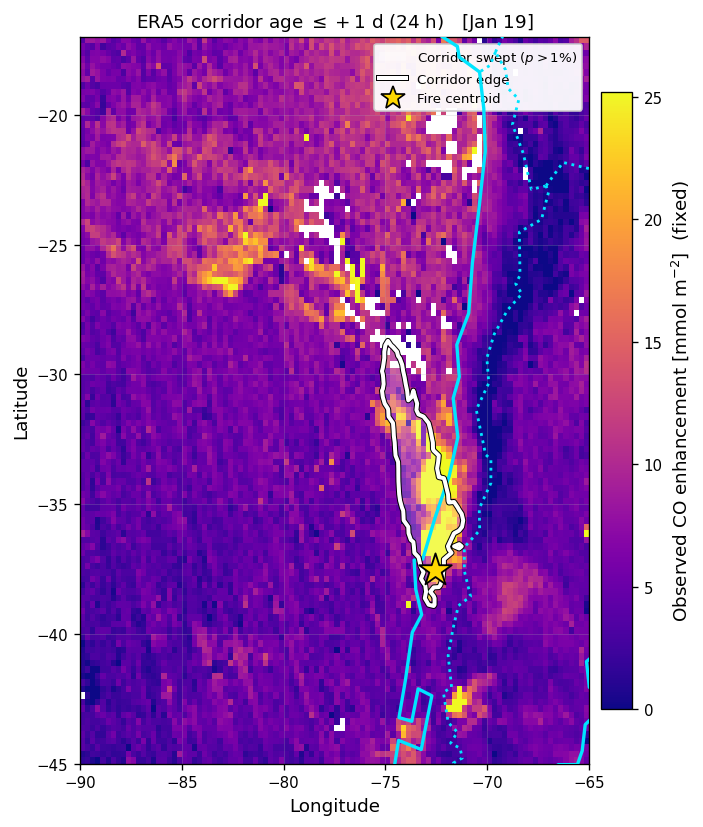

Saved /Users/maperezc/Downloads/wildfires/outputs/transport_temporal/frame_corridor_+2d.png


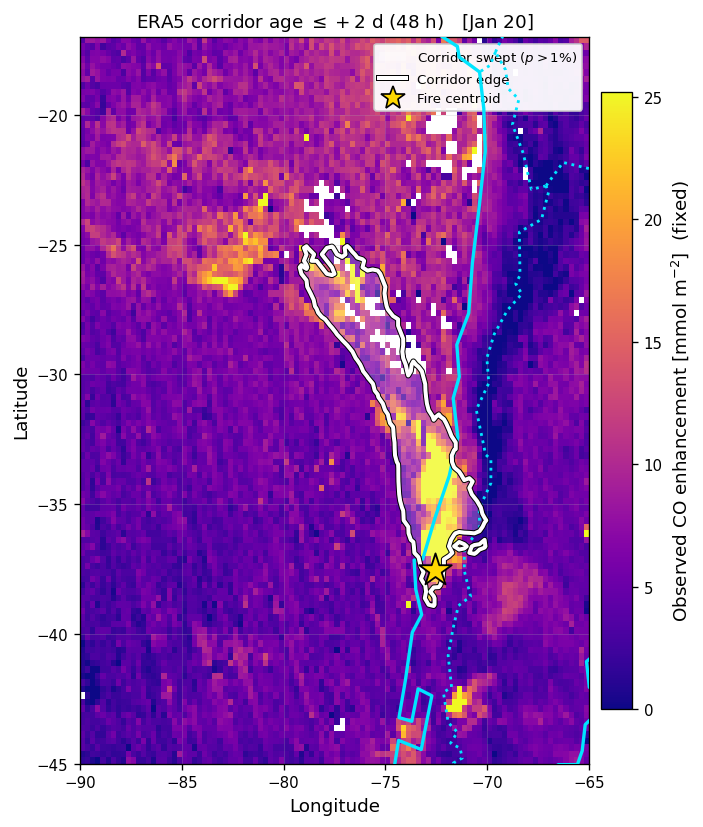

Saved /Users/maperezc/Downloads/wildfires/outputs/transport_temporal/frame_corridor_+3d.png


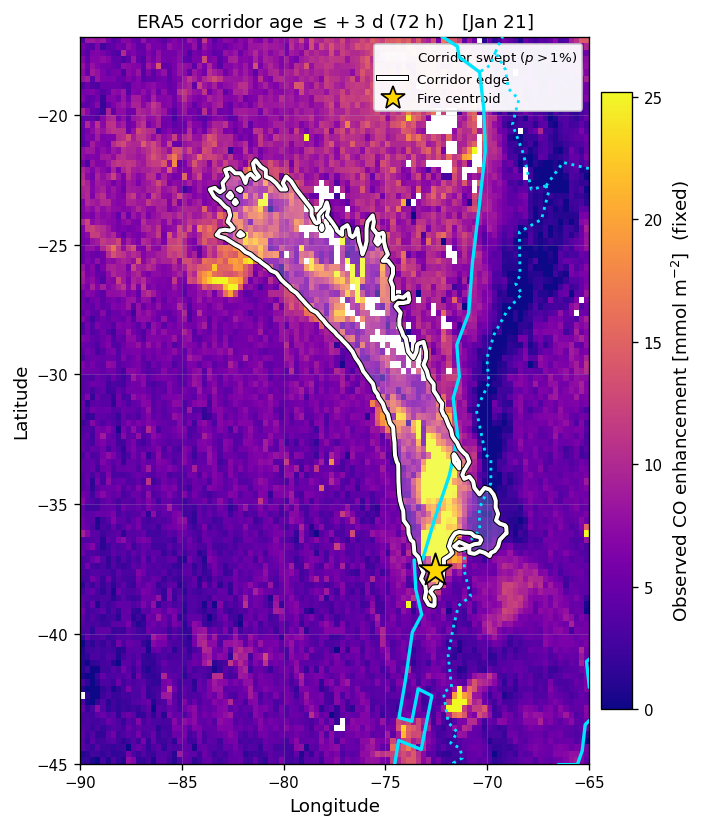

Saved /Users/maperezc/Downloads/wildfires/outputs/transport_temporal/frame_corridor_+4d.png


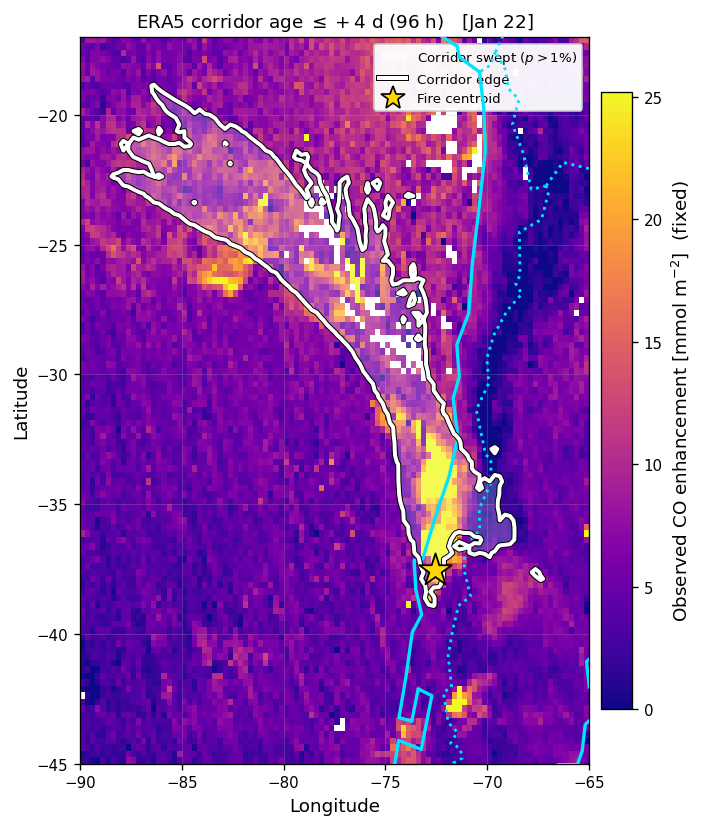

In [21]:
# ── Render + save the four individual frames ─────────────────────────────────
for ov in OVERPASSES:
    fig, ax = plt.subplots(figsize=(6.0, 7.0))
    m = draw_frame(ax, ov['offset'], ov['dt'])
    cb = fig.colorbar(m, ax=ax, shrink=0.85, pad=0.02)
    cb.set_label('Observed CO enhancement [mmol m$^{-2}$]  (fixed)')
    fig.tight_layout()
    out = OUT_DIR / f"frame_corridor_+{ov['offset']}d.png"
    fig.savefig(out, dpi=150, bbox_inches='tight')
    print(f'Saved {out}')
    plt.show()


## Assemble the timelapse GIF

Fixed figure size, no `tight` bbox (so all frames share exact pixel dimensions),
written with Pillow. `+4 d` (full 96-h corridor) is held longer for a natural
loop pause.

In [22]:
# ── Build the GIF ────────────────────────────────────────────────────────────
from PIL import Image

FIG_SIZE = (6.0, 7.0)
FRAME_DPI = 130
PER_FRAME_MS = 1200
LAST_FRAME_MS = 2200

def render_frame_image(offset, dt) -> Image.Image:
    fig, ax = plt.subplots(figsize=FIG_SIZE)
    m = draw_frame(ax, offset, dt)
    cb = fig.colorbar(m, ax=ax, shrink=0.85, pad=0.02)
    cb.set_label('Observed CO enhancement [mmol m$^{-2}$]  (fixed)')
    fig.subplots_adjust(left=0.11, right=0.99, top=0.88, bottom=0.08)
    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=FRAME_DPI)   # NO bbox_inches='tight'
    plt.close(fig)
    buf.seek(0)
    return Image.open(buf).convert('RGB')

frames = [render_frame_image(ov['offset'], ov['dt']) for ov in OVERPASSES]
base_size = frames[0].size
assert all(f.size == base_size for f in frames), \
    f'Frame size mismatch {[f.size for f in frames]} — GIF requires identical dimensions'

durations = [PER_FRAME_MS] * (len(frames) - 1) + [LAST_FRAME_MS]
gif_path = OUT_DIR / 'fig_transport_corridor_timelapse.gif'
frames[0].save(gif_path, save_all=True, append_images=frames[1:],
               duration=durations, loop=0, disposal=2)
print(f'Saved timelapse ({len(frames)} frames, {base_size[0]}x{base_size[1]} px): {gif_path}')


Saved timelapse (4 frames, 780x910 px): /Users/maperezc/Downloads/wildfires/outputs/transport_temporal/fig_transport_corridor_timelapse.gif


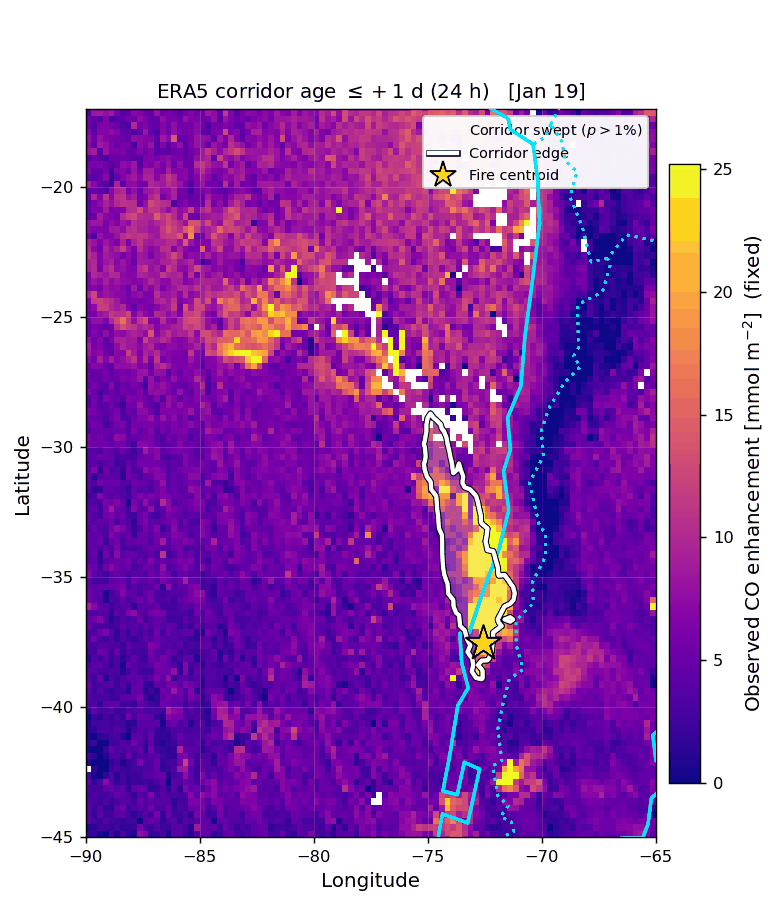

In [23]:
from IPython.display import Image as IPyImage, display
display(IPyImage(filename=str(gif_path)))


## Static filmstrip (paper-friendly still)

A single 1x4 PNG of the four frames for the manuscript PDF (which cannot embed a
GIF). One shared colourbar and legend.

Saved /Users/maperezc/Downloads/wildfires/outputs/transport_temporal/fig_transport_corridor_filmstrip.png


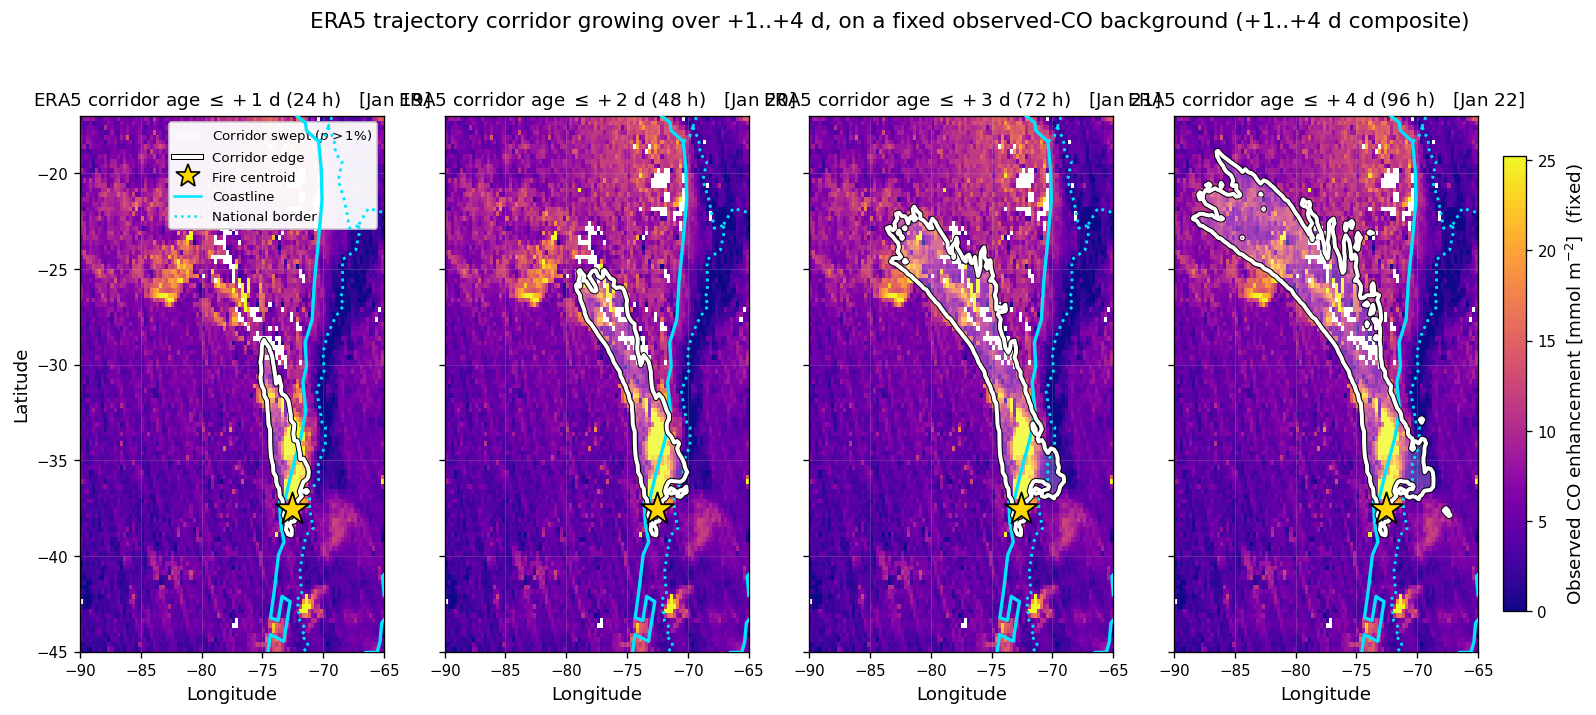

In [11]:
# ── Static 1x4 filmstrip ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(18.0, 5.8), sharey=True)
for k, (ax, ov) in enumerate(zip(axes, OVERPASSES)):
    m = draw_frame(ax, ov['offset'], ov['dt'], show_legend=(k == 0), show_ylabel=(k == 0))
    if k > 0:
        ax.set_ylabel('')
fig.suptitle('ERA5 trajectory corridor growing over +1..+4 d, on a fixed observed-CO '
             'background (+1..+4 d composite)', fontsize=13, y=1.03)
cb = fig.colorbar(m, ax=axes, shrink=0.85, pad=0.015, location='right')
cb.set_label('Observed CO enhancement [mmol m$^{-2}$]  (fixed)')
strip_path = OUT_DIR / 'fig_transport_corridor_filmstrip.png'
fig.savefig(strip_path, dpi=200, bbox_inches='tight')
print(f'Saved {strip_path}')
plt.show()


## Summary

Produced under `outputs/transport_temporal/`:

- **`fig_transport_corridor_timelapse.gif`** — the requested timelapse: a
  **fixed** observed-CO background (panel-a composite) with the ERA5 trajectory
  corridor **growing** from age ≤ +1 d to the full ≤ +4 d (96 h) footprint.
- `frame_corridor_+1d.png` .. `frame_corridor_+4d.png` — individual frames.
- `fig_transport_corridor_filmstrip.png` — static 1x4 strip.

ERA5-driven transport only. The ensemble is re-run from the nb05 priors/seed and
its +96 h corridor is asserted equal to `outputs/pathway/corridor_prob.npy`; the
per-day corridors come from age-windowed (`time_window_h`) slicing of the same
trajectories.
